# Honey adulteration detection from NIR spectra

This notebook follows the public-data study from the dataset audits through the model comparison, external transfer, and follow-up design. It reads the saved study outputs and runs the independent numerical checks. A standard run uses the files in this repository and takes seconds.

**Main findings.** The training-selected classical procedure reached 74.9% balanced accuracy on held-out Auckland brands. The strongest neural model, the MLP, was 7.3 percentage points lower, with a conditional 95% interval of −15.9 to +6.2 points. Transfer was weak. XGBoost detected 8 of 31 labeled adulterated Argentine preparations. All three models in the matched-window experiment flagged all 80 Padua samples.

[Manuscript](../paper/honey_adulteration_manuscript.pdf) · [Reproduction guide](../paper/REPRODUCE.md) · [Follow-up protocol](../FOLLOWUP.md) · [Pilot protocol](../PILOT.md)

1. [Data and validation](#1-data-and-validation)
2. [Seven-model benchmark](#2-seven-model-benchmark)
3. [Robustness and computing cost](#3-robustness-and-computing-cost)
4. [Matched-window transfer to Padua](#4-matched-window-transfer-to-padua)
5. [Pilot and follow-up tracker](#5-pilot-and-follow-up-tracker)
6. [Audit trail and reproduction](#6-audit-trail-and-reproduction)


In [1]:
from pathlib import Path
import json
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'benchmark.py').is_file())
RESULTS = ROOT / 'results'
TRANSFER = RESULTS / 'padua_transfer'
MODEL_ORDER = ['PLS-DA', 'SVM', 'Random Forest', 'XGBoost', 'MLP', '1D-CNN', 'Spectral Transformer', 'Selected classical']
pd.set_option('display.max_columns', 24)

def read(filename, directory=RESULTS):
    return pd.read_csv(directory / filename)

def load_record(filename, directory=RESULTS):
    return json.loads((directory / filename).read_bytes())

def percent(table, columns):
    shown = table.copy()
    shown[list(columns)] = (100 * shown[list(columns)]).round(1)
    return shown


## 1 Data and validation

Auckland image segments were aggregated by image key and evaluated with whole brands held out. Argentina contributes labeled preparations for one-way transfer. The Padua workbook contributes ordinary-honey FOSS spectra for evaluating flag frequency in a separate experiment. Padua lacks adjudicated adulteration labels.

[Auckland release](https://doi.org/10.17608/k6.auckland.16441686.v1) · [Argentine data source](https://nirpyresearch.com/aquagrams-python-matplotlib/) · [Padua release](https://doi.org/10.25430/researchdata.cab.unipd.it.00001770)


In [2]:
run = load_record('run.json')
source_names = {'auckland': 'Auckland', 'nirpy': 'Argentina'}
inventory = pd.DataFrame([
    {'cohort': source_names[name], 'observations': item['observations'],
     'pure labels': int(item['class_counts']['0']), 'adulterated labels': int(item['class_counts']['1']),
     'raw rows': item['raw_rows']}
    for name, item in run['datasets'].items()
])
padua_flags = read('padua_flag_rates.csv', TRANSFER)
inventory.loc[len(inventory)] = ['Padua FOSS', int(padua_flags['samples'].max()), None, None, None]
display(inventory)

auckland = read('auckland_observations.csv')
display(auckland.groupby(['group', 'nominal_pct']).size().unstack(fill_value=0).rename_axis('brand'))
print('Run seed:', run['seed'], '| CPU threads:', run['threads'], '| Python:', run['python'])


,cohort,observations,pure labels,adulterated labels,raw rows
0,Auckland,335,42,293,8675
1,Argentina,37,6,31,165
2,Padua FOSS,80,None,None,None


nominal_pct,0,5,10,25,50
brand,,,,,
C1,6,6,12,12,12
C10,6,24,18,18,24
C4,0,6,6,6,5
C5,0,6,0,6,6
C7,18,18,18,12,12
C8,6,6,6,6,6
C9,6,12,6,12,12


Run seed: 20261123 | CPU threads: 1 | Python: 3.13.0


The baseline benchmark used nested grouped model selection. Preprocessing learned from training partitions only. The wavelength comparison in Section 4 additionally reserved separate source brands for cutoff calibration. The matched-window models were frozen before scoring Padua.


In [3]:
original_splits = load_record('splits.json')
calibrated_splits = load_record('split_manifest.json', TRANSFER)
display(pd.DataFrame([{k: split[k] for k in ('test', 'development_brands', 'calibration_brands')}
                      for split in calibrated_splits if split['window'] == '850-1000']))
print(f'Original split records: {len(original_splits)} | Matched-window and reference split records: {len(calibrated_splits)}')


,test,development_brands,calibration_brands
0,C1,"[C4, C5, C7, C9]","[C10, C8]"
1,C10,"[C4, C5, C7, C8]","[C1, C9]"
2,C4,"[C1, C10, C5, C8]","[C7, C9]"
3,C5,"[C1, C10, C4, C8]","[C7, C9]"
4,C7,"[C1, C10, C4, C5]","[C8, C9]"
5,C8,"[C10, C4, C5, C7]","[C1, C9]"
6,C9,"[C4, C5, C7, C8]","[C1, C10]"
7,Padua,"[C1, C10, C4, C5, C7]","[C8, C9]"


Original split records: 8 | Matched-window and reference split records: 15


## 2 Seven-model benchmark

Balanced accuracy averages sensitivity and specificity. Auckland AUC averages the eligible held-out brands. Argentina AUC uses the external preparation labels and the single source fit. Compare the class-specific rates alongside balanced accuracy because the number of pure controls is small.


**Auckland held-out brands**

,Balanced accuracy %,Conditional 95% interval,Specificity %,Sensitivity %,Accuracy %,Macro F1,ROC AUC,False positives,False negatives
model,,,,,,,,,
PLS-DA,57.3,46.4–63.3,19.0,95.6,86.0,0.588,0.668,34,13
SVM,73.1,56.0–82.0,81.0,65.2,67.2,0.579,0.692,8,102
Random Forest,55.4,43.9–76.3,23.8,87.0,79.1,0.551,0.745,32,38
XGBoost,71.2,56.1–91.9,54.8,87.7,83.6,0.679,0.867,19,36
MLP,67.6,54.8–82.0,69.0,66.2,66.6,0.559,0.662,13,99
1D-CNN,66.6,55.8–85.1,66.7,66.6,66.6,0.555,0.537,14,98
Spectral Transformer,53.0,43.8–68.0,26.2,79.9,73.1,0.518,0.651,31,59
Selected classical,74.9,57.3–85.6,81.0,68.9,70.4,0.605,0.702,8,91


**Argentina external cohort**

,Balanced accuracy %,Specificity %,Sensitivity %,Accuracy %,Macro F1,ROC AUC,False positives,False negatives
model,,,,,,,,
PLS-DA,39.2,33.3,45.2,43.2,0.366,0.468,4,17
SVM,39.2,33.3,45.2,43.2,0.366,0.419,4,17
Random Forest,43.8,16.7,71.0,62.2,0.442,0.551,5,9
XGBoost,62.9,100.0,25.8,37.8,0.377,0.589,0,23
MLP,59.7,100.0,19.4,32.4,0.324,0.731,0,25
1D-CNN,53.2,100.0,6.5,21.6,0.207,0.484,0,29
Spectral Transformer,45.2,0.0,90.3,75.7,0.431,0.371,6,3
Selected classical,62.9,100.0,25.8,37.8,0.377,0.589,0,23


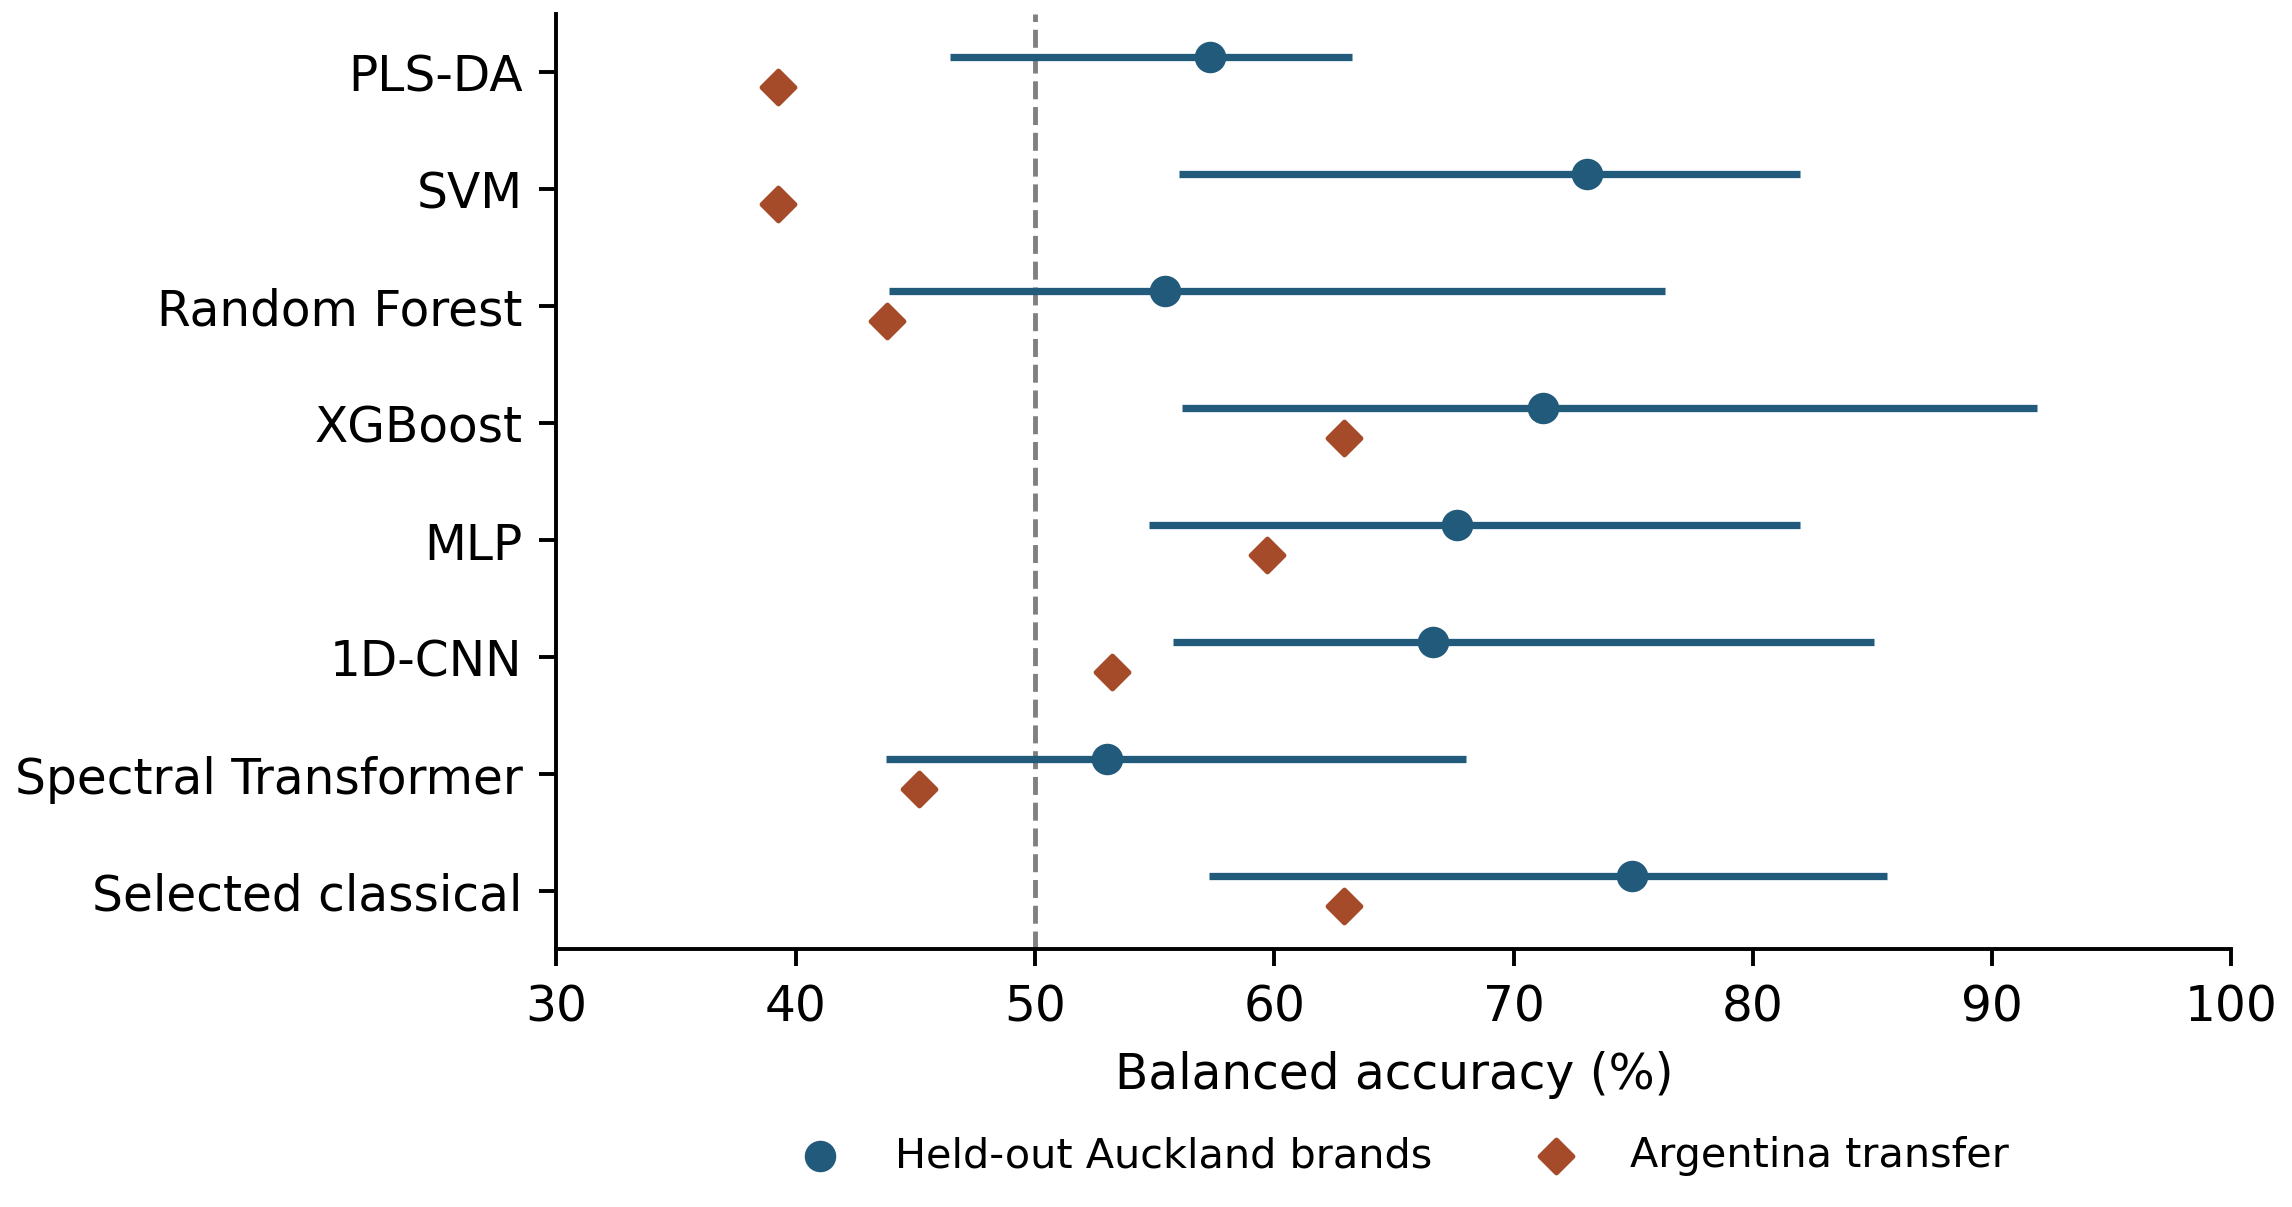

In [4]:
metrics = read('metrics.csv')
clean = metrics.loc[metrics['scenario'].eq('clean')]
intervals = read('brand_uncertainty.csv').set_index('model')
rates = {'balanced_accuracy': 'Balanced accuracy %', 'specificity': 'Specificity %',
         'sensitivity': 'Sensitivity %', 'accuracy': 'Accuracy %'}
other = {'macro_f1': 'Macro F1', 'roc_auc_mean_within_fold': 'ROC AUC',
         'false_positives': 'False positives', 'false_negatives': 'False negatives'}
for protocol, title in [('held_out_brand', 'Auckland held-out brands'), ('cross_dataset', 'Argentina external cohort')]:
    rows = clean.loc[clean['protocol'].eq(protocol)].set_index('model').loc[MODEL_ORDER]
    display(Markdown(f'**{title}**'))
    shown = percent(rows[list(rates) + list(other)], rates).rename(columns=rates | other)
    if protocol == 'held_out_brand':
        shown.insert(1, 'Conditional 95% interval', [f'{100 * lo:.1f}–{100 * hi:.1f}'
                                                    for lo, hi in intervals.loc[rows.index, ['ci95_low', 'ci95_high']].itertuples(index=False)])
    display(shown.round(3))
display(Image(filename=str(ROOT / 'paper' / 'figures' / 'benchmark_results.png'), width=760))


### Paired effects and test resolution

The brand bootstrap intervals condition on the saved held-out predictions. Every contrast contributed at most six nonzero brand differences. With the observed ties, the smallest attainable one-sided probability was 0.015625, above the first Holm cutoff of 0.01. The directional tests are exploratory, and the intervals express uncertainty about the size of the differences.


In [5]:
comparisons = read('comparisons.csv')
contrast_rates = {'difference': 'Difference (pp)', 'ci95_low': '95% low (pp)', 'ci95_high': '95% high (pp)'}
contrast_labels = {'nonzero_brand_contrasts': 'Nonzero brands', 'min_attainable_one_sided_p': 'Minimum p',
                   'p_one_sided': 'One-sided p', 'p_holm': 'Holm p'}
display(percent(comparisons[['model', 'baseline', *contrast_rates, *contrast_labels]], contrast_rates)
        .rename(columns=contrast_rates | contrast_labels).round(6))


,model,baseline,Difference (pp),95% low (pp),95% high (pp),Nonzero brands,Minimum p,One-sided p,Holm p
0,MLP,Selected classical,-7.3,-15.9,6.2,6,0.015625,0.84375,1.0
1,1D-CNN,Selected classical,-8.3,-16.7,7.4,6,0.015625,0.81250,1.0
2,Spectral Transformer,Selected classical,-21.9,-36.2,0.9,5,0.031250,0.87500,1.0
3,1D-CNN,MLP,-1.0,-4.5,6.2,3,0.125000,0.62500,1.0
4,Spectral Transformer,1D-CNN,-13.6,-26.1,-0.1,5,0.031250,0.90625,1.0


### Brand, dose, and syrup results

A dash indicates an undefined class-specific or balanced result. Two Auckland brands contain only adulterated observations. The detailed tables preserve the denominators and confusion counts.


In [6]:
def matrix(table, index, value):
    return (100 * table.pivot(index=index, columns='model', values=value).reindex(columns=MODEL_ORDER)).round(1)

display(Markdown('**Auckland balanced accuracy by brand (%)**'))
display(matrix(read('by_brand.csv'), 'fold', 'balanced_accuracy'))
display(Markdown('**Auckland sensitivity by nominal dose (%)**'))
dose = read('by_dose.csv')
display(matrix(dose.loc[dose['nominal_pct'].gt(0)], 'nominal_pct', 'sensitivity'))
display(Markdown('**Argentina sensitivity by released adulterant code (%)**'))
argentina = read('external_by_adulterant.csv')
display(matrix(argentina.loc[argentina['n_adulterated'].gt(0)], 'adulterant', 'sensitivity'))


**Auckland balanced accuracy by brand (%)**

model,PLS-DA,SVM,Random Forest,XGBoost,MLP,1D-CNN,Spectral Transformer,Selected classical
fold,,,,,,,,
C1,48.8,64.3,72.6,75.0,54.8,54.8,63.1,64.3
C10,65.5,78.0,83.3,83.3,92.3,92.3,71.4,78.0
C4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C7,64.2,70.8,47.5,52.8,62.8,58.6,51.9,70.8
C8,43.8,70.8,31.2,91.7,62.5,64.6,27.1,91.7
C9,50.0,40.5,50.0,92.9,45.2,48.8,48.8,40.5


**Auckland sensitivity by nominal dose (%)**

model,PLS-DA,SVM,Random Forest,XGBoost,MLP,1D-CNN,Spectral Transformer,Selected classical
nominal_pct,,,,,,,,
5.0,96.2,48.7,88.5,84.6,56.4,56.4,79.5,52.6
10.0,93.9,50.0,80.3,86.4,63.6,63.6,74.2,56.1
25.0,94.4,73.6,87.5,91.7,72.2,70.8,79.2,79.2
50.0,97.4,87.0,90.9,88.3,72.7,75.3,85.7,87.0


**Argentina sensitivity by released adulterant code (%)**

model,PLS-DA,SVM,Random Forest,XGBoost,MLP,1D-CNN,Spectral Transformer,Selected classical
adulterant,,,,,,,,
GLU,25.0,25.0,75.0,37.5,25.0,25.0,100.0,37.5
JMAF,53.8,53.8,84.6,23.1,23.1,0.0,92.3,23.1
RS,50.0,50.0,50.0,20.0,10.0,0.0,80.0,20.0


## 3 Robustness and computing cost

Perturbations were applied to held-out spectra, with the fitted models held fixed. Negative changes indicate a loss relative to each model's own clean balanced accuracy. Runtime is a single-thread CPU measurement and depends on the host and software build.


scenario,1% noise,5% noise,10% tilt,5 nm shift
model,,,,
PLS-DA,2.2,2.9,9.2,-6.2
SVM,0.8,-3.9,1.0,-15.7
Random Forest,0.3,-0.5,-0.0,-5.6
XGBoost,-1.2,-6.0,-7.7,-16.3
MLP,1.2,-3.6,1.0,-2.5
1D-CNN,0.2,-1.4,-0.3,-5.1
Spectral Transformer,0.8,-3.2,1.2,-7.3
Selected classical,-1.0,-7.3,-4.1,-19.6


,Refit s,Search s,Single µs,Batch µs per spectrum,Model KiB,Neural parameters
model,,,,,,
PLS-DA,0.0019,0.0208,210.5,2.1133,50.8906,NaN
SVM,0.0029,0.0366,272.9,5.2488,47.3408,NaN
Random Forest,0.2173,2.7238,10952.5,91.9648,291.4209,NaN
XGBoost,0.1108,0.8668,818.9,8.9652,133.4062,NaN
MLP,0.3561,3.3186,325.0,3.8848,8.5684,2113.0
1D-CNN,0.9548,8.5495,720.7,19.6051,11.6973,2913.0
Spectral Transformer,4.6082,36.8849,1210.4,61.9098,153.7188,38881.0


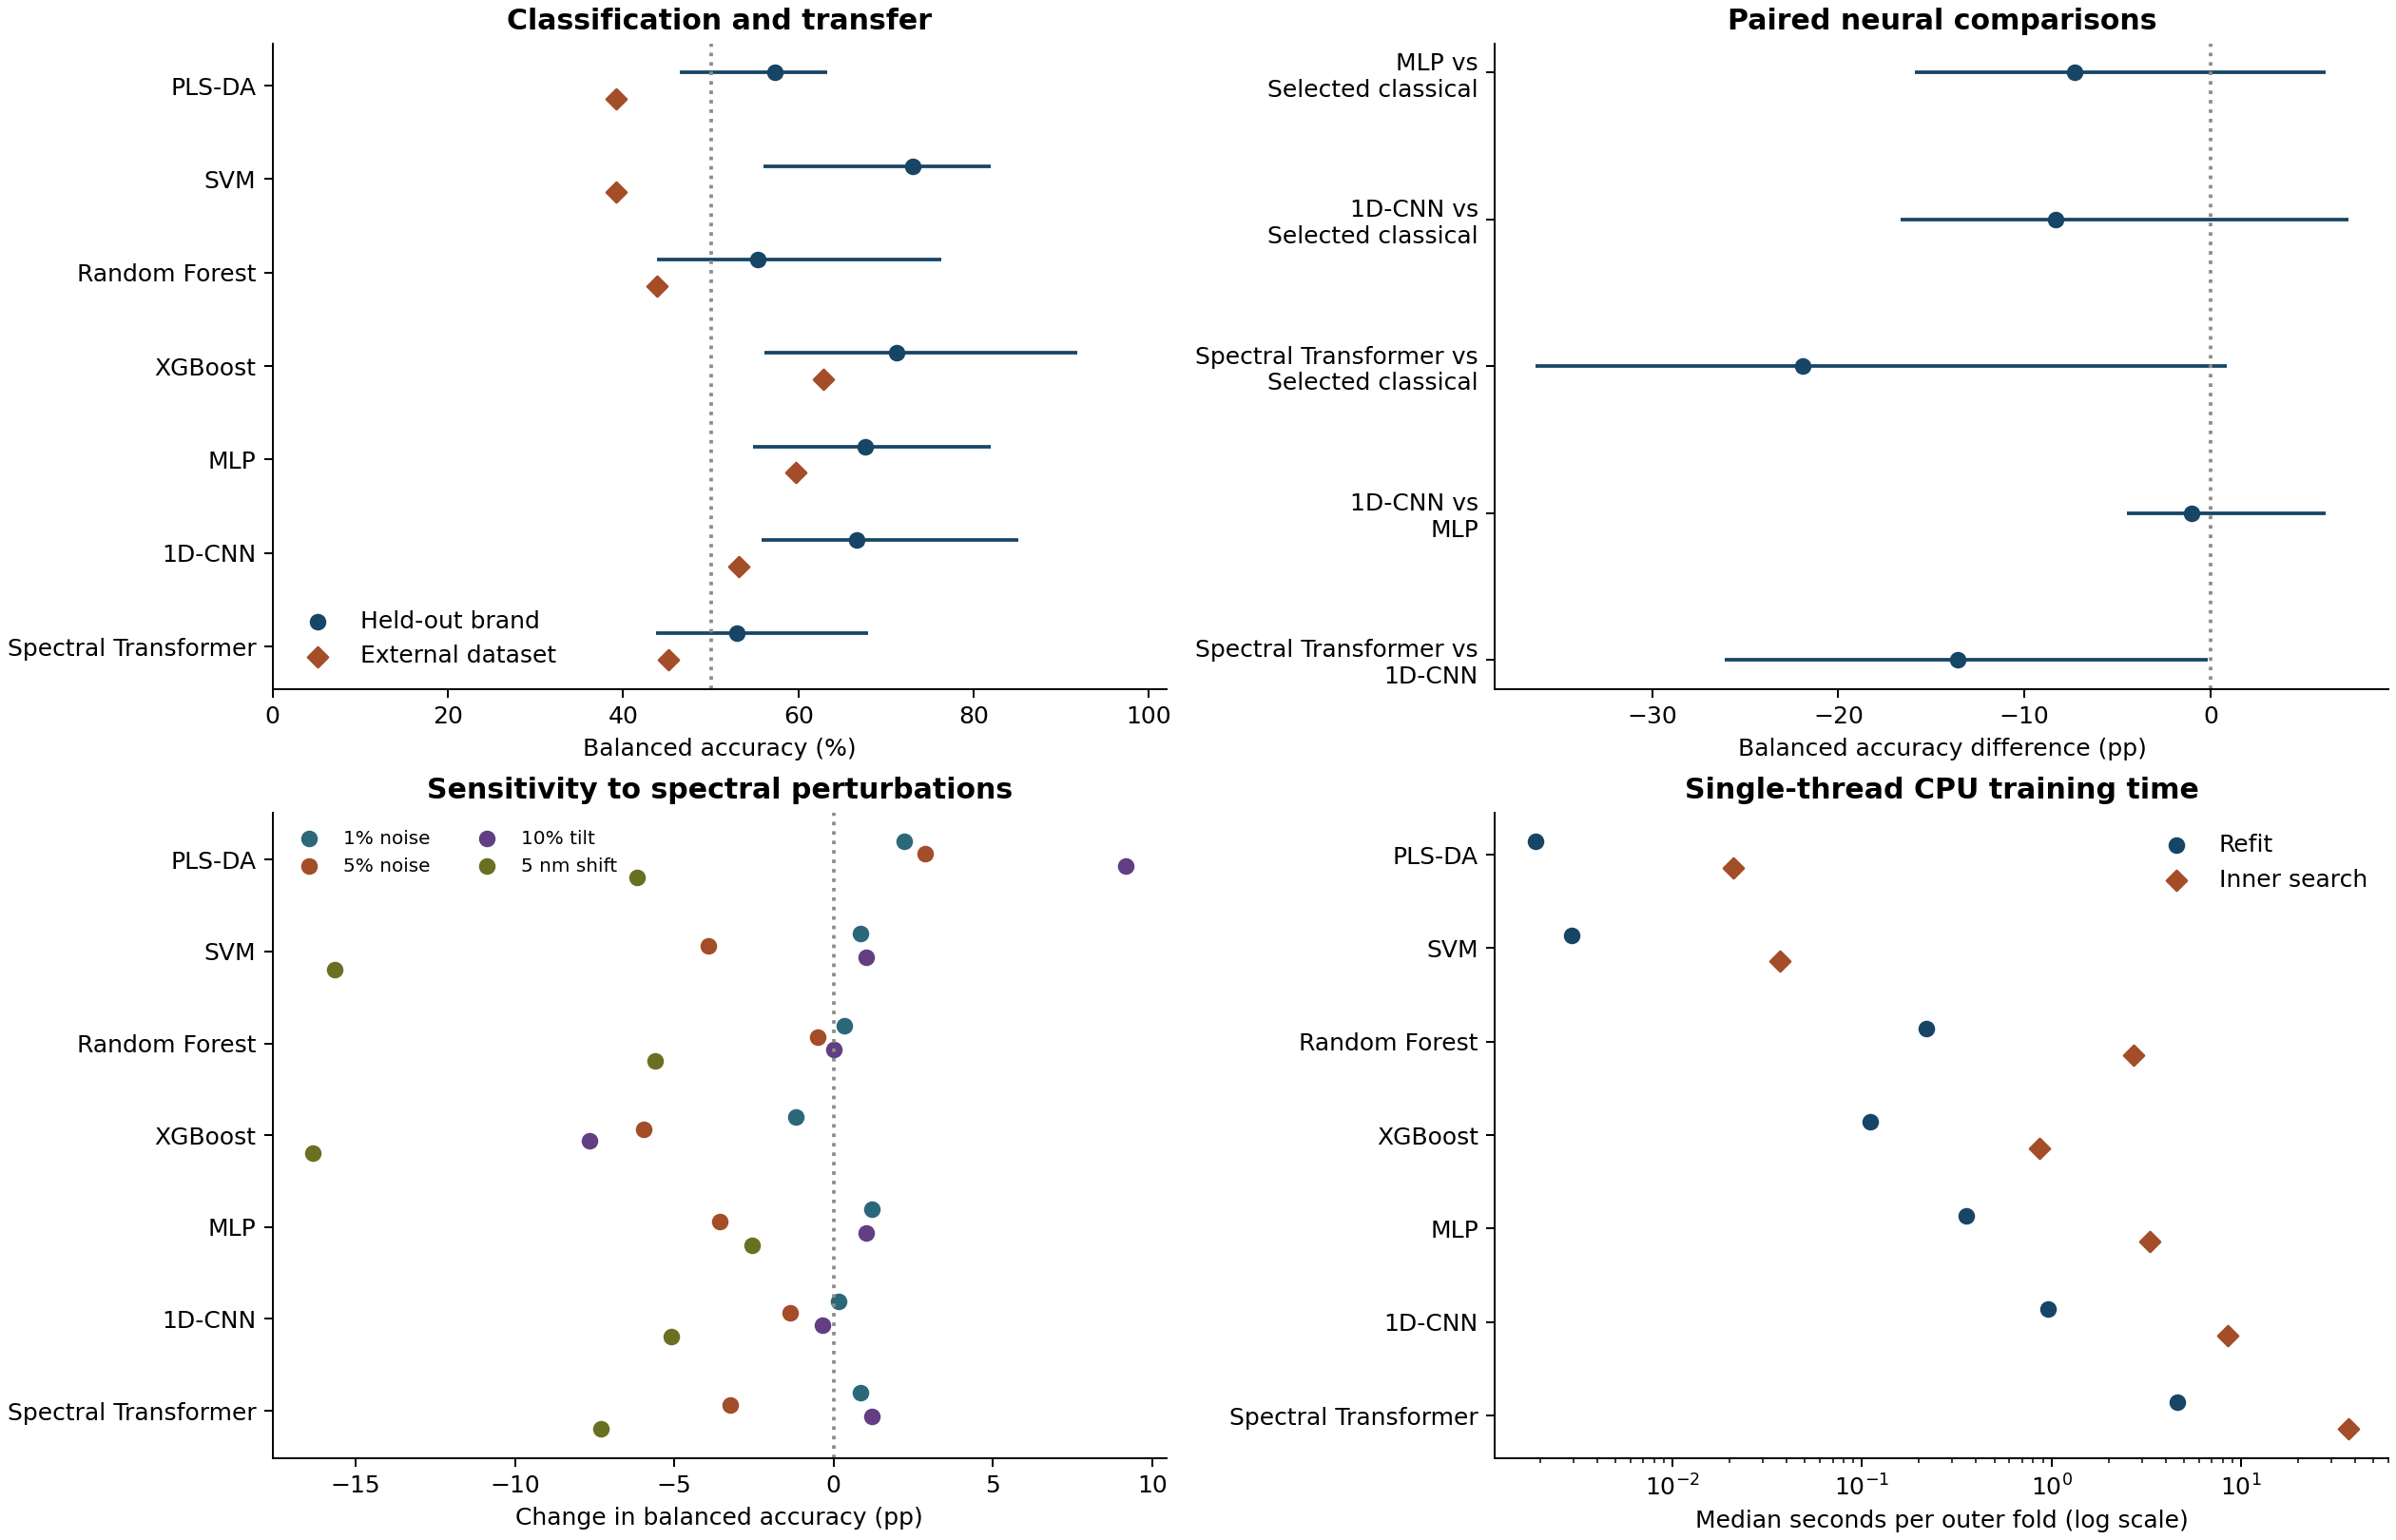

In [7]:
robustness = read('robustness.csv')
stress = {'noise_1pct': '1% noise', 'noise_5pct': '5% noise', 'tilt_10pct': '10% tilt', 'shift_5nm': '5 nm shift'}
changes = robustness.assign(**{'Change (pp)': 100 * robustness['delta_from_clean']})
display(changes.pivot(index='model', columns='scenario', values='Change (pp)').loc[MODEL_ORDER, list(stress)]
        .rename(columns=stress).round(1))

cost = read('efficiency.csv').set_index('model').loc[MODEL_ORDER[:-1]]
cost['model_KiB'] = cost['serialized_bytes'] / 1024
cost_columns = {'final_fit_s': 'Refit s', 'inner_search_s': 'Search s', 'batch_1_us_per_spectrum': 'Single µs',
                'batch_128_us_per_spectrum': 'Batch µs per spectrum', 'model_KiB': 'Model KiB',
                'trainable_parameters': 'Neural parameters'}
display(cost[list(cost_columns)].rename(columns=cost_columns).round(4))
display(Image(filename=str(RESULTS / 'benchmark.png'), width=900))


## 4 Matched-window transfer to Padua

SVM, XGBoost, and MLP were compared on the original and overlapping wavelength windows with the same brand assignments. The empirical calibration target was 90% specificity, with realized held-out specificity displayed below. Freezing source thresholds keeps Padua outcomes independent of cutoff selection.


In [8]:
transfer_rates = read('auckland_metrics.csv', TRANSFER)
transfer_columns = {'specificity': 'Specificity %', 'sensitivity_5pct': 'Sensitivity at 5% %',
                    'sensitivity_10pct': 'Sensitivity at 10% %', 'balanced_accuracy': 'Balanced accuracy %'}
display(percent(transfer_rates[['model', 'window', *transfer_columns]], transfer_columns).rename(columns=transfer_columns))
paired = read('paired_differences.csv', TRANSFER)
paired_columns = {'matched_minus_reference': 'Matched minus reference (pp)', 'ci95_low': '95% low (pp)',
                  'ci95_high': '95% high (pp)'}
display(percent(paired, paired_columns).rename(columns=paired_columns))


,model,window,Specificity %,Sensitivity at 5% %,Sensitivity at 10% %,Balanced accuracy %
0,SVM,780-1000,78.6,21.8,9.1,52.3
1,XGBoost,780-1000,95.2,53.8,59.1,78.8
2,MLP,780-1000,85.7,34.6,36.4,63.2
3,SVM,850-1000,73.8,60.3,65.2,73.3
4,XGBoost,850-1000,90.5,52.6,63.6,80.1
5,MLP,850-1000,78.6,50.0,54.5,69.5


,model,endpoint,Matched minus reference (pp),95% low (pp),95% high (pp),supporting_brands
0,SVM,specificity,-4.8,-42.9,50.0,5
1,SVM,sensitivity_5pct,38.5,-5.2,73.1,7
2,SVM,sensitivity_10pct,56.1,27.8,81.5,6
3,XGBoost,specificity,-4.8,-33.3,16.7,5
4,XGBoost,sensitivity_5pct,-1.3,-16.7,16.7,7
5,XGBoost,sensitivity_10pct,4.5,-25.0,33.3,6
6,MLP,specificity,-7.1,-36.7,8.3,5
7,MLP,sensitivity_5pct,15.4,1.4,45.0,7
8,MLP,sensitivity_10pct,18.2,0.0,50.0,6


The Padua no-spike cohort is a flag-rate stress test. Feature counts use each Auckland development feature’s observed range after standard normal variate normalization. They describe spectral shift under the frozen pipeline. They do not identify its physical cause.


,model,representation,flags,samples,Flag rate %
0,SVM,reflectance_proxy,80,80,100.0
1,XGBoost,reflectance_proxy,80,80,100.0
2,MLP,reflectance_proxy,80,80,100.0
3,SVM,as_recorded_absorbance,80,80,100.0
4,XGBoost,as_recorded_absorbance,80,80,100.0
5,MLP,as_recorded_absorbance,80,80,100.0


,observations,minimum,median,maximum
cohort,,,,
as_recorded_absorbance,80,41,41.0,44
auckland_calibration_pure,12,0,15.0,31
reflectance_proxy,80,28,30.0,32


Distinct scores
model   representation                         
MLP     as_recorded_absorbance               80
        reflectance_proxy                    80
SVM     as_recorded_absorbance               80
        reflectance_proxy                    80
XGBoost as_recorded_absorbance                2
        reflectance_proxy                     1

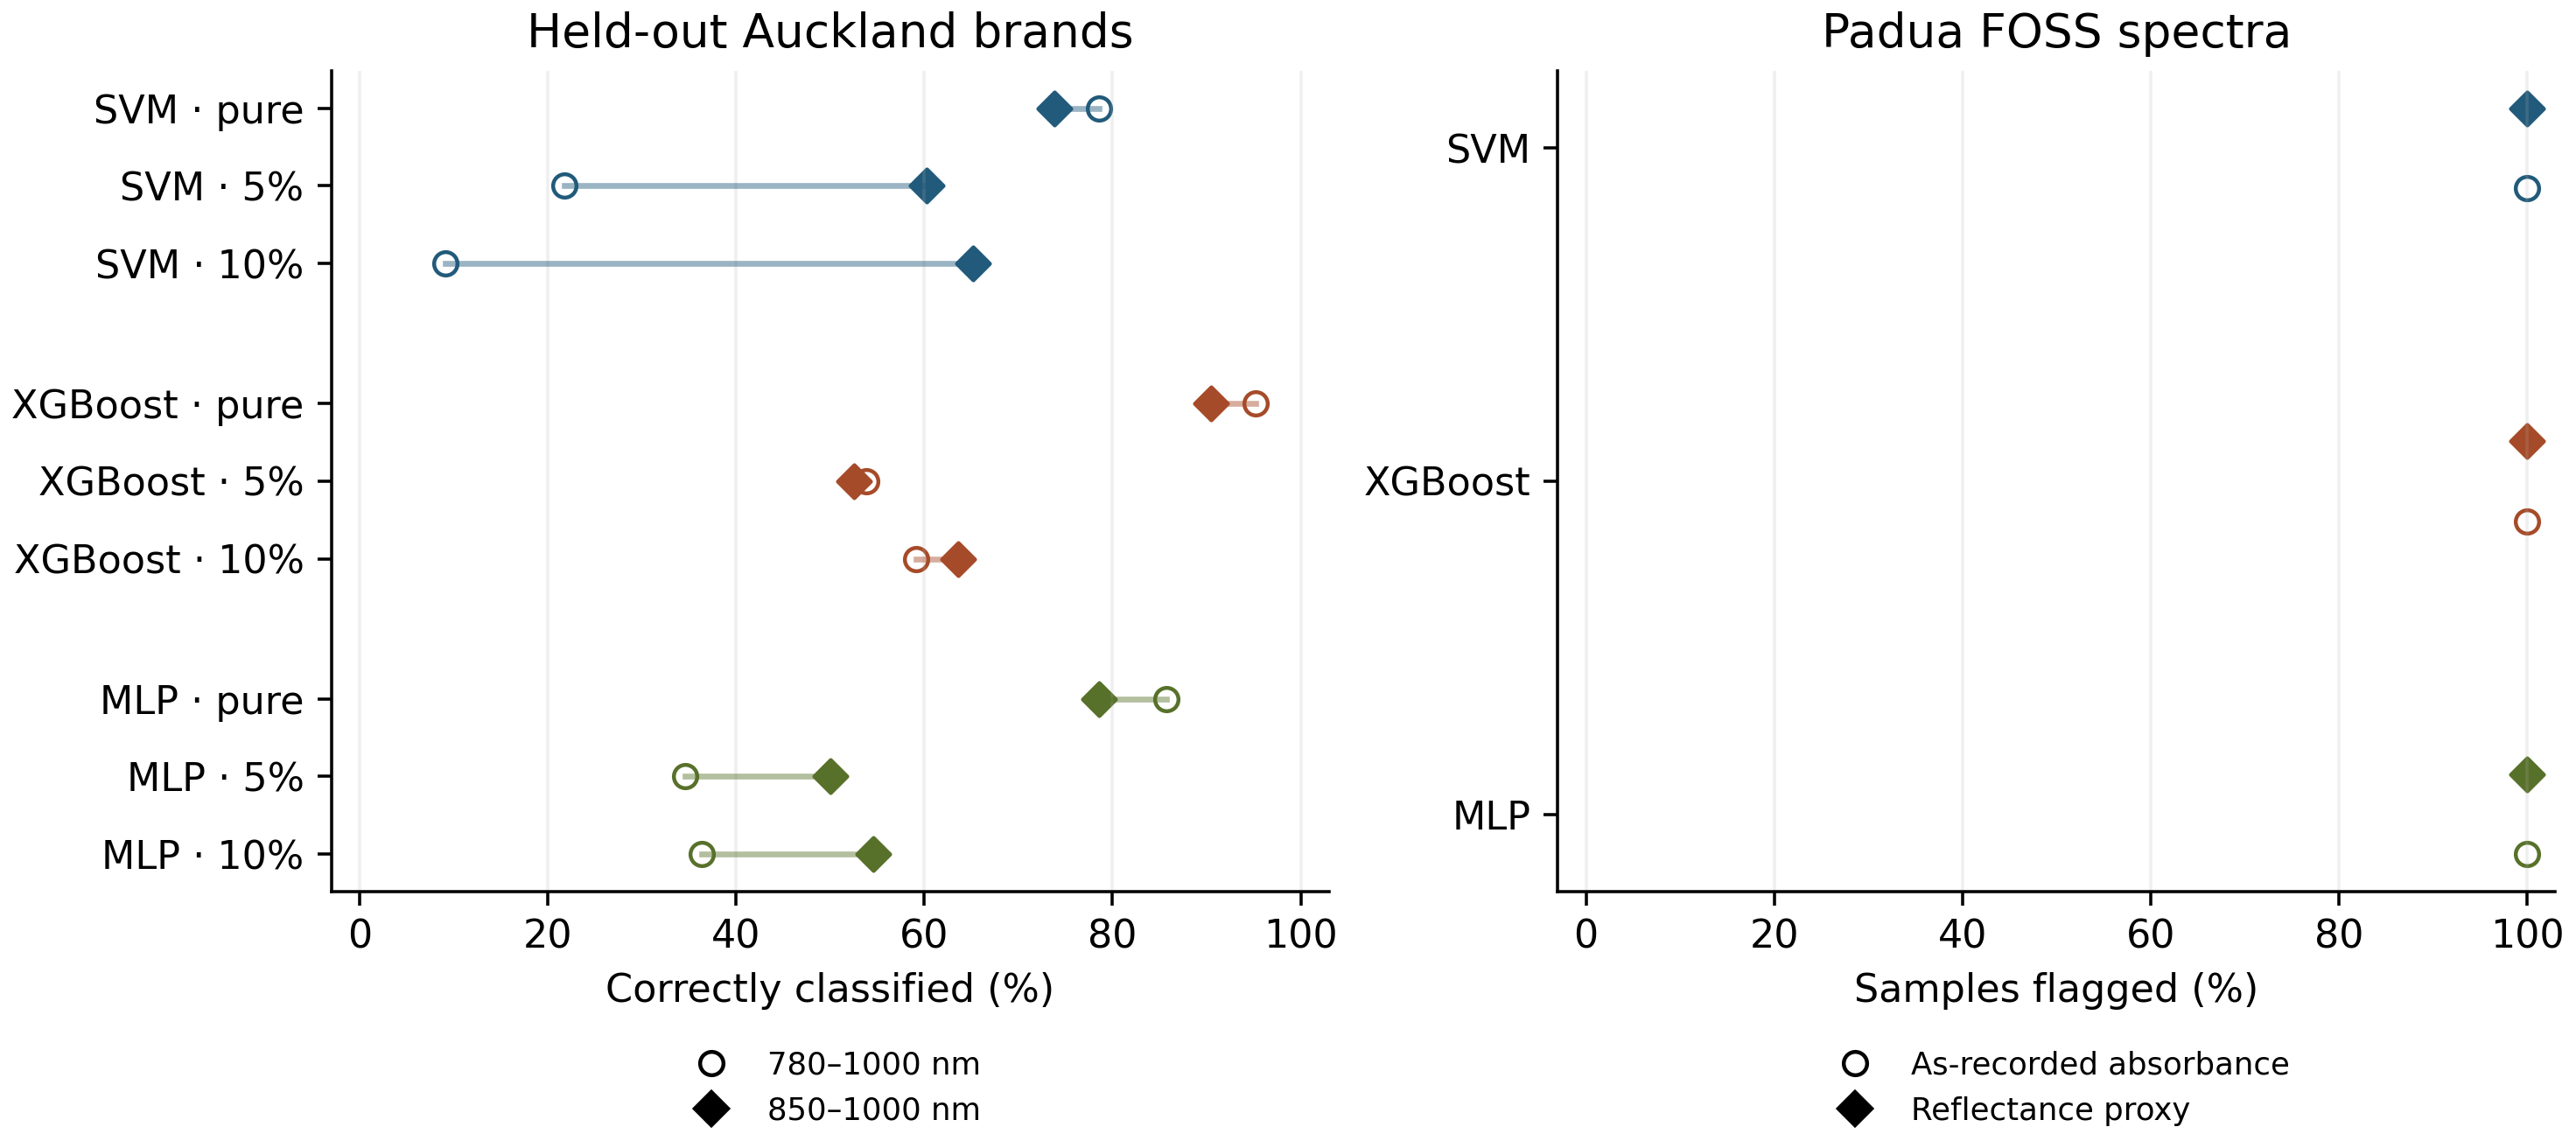

In [9]:
display(percent(padua_flags, ['flag_rate']).rename(columns={'flag_rate': 'Flag rate %'}))
display(read('feature_support.csv', TRANSFER).groupby('cohort').features_outside_development_range
        .agg(observations='count', minimum='min', median='median', maximum='max'))
display(read('padua_predictions.csv', TRANSFER).groupby(['model', 'representation']).score.nunique()
        .rename('Distinct scores').to_frame())
display(Image(filename=str(TRANSFER / 'padua_transfer.png'), width=850))


## 5 Pilot and follow-up tracker

These outputs document the planned prospective work and archived demonstrations. The retrospective demonstrations use surrogate lot IDs and carry no prospective decision. The formal lot-count estimate depends on its assumed true rates.


In [10]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from followup_stats import sample_size_plan

pilot = load_record('pilot_plan/design.json')
archive_demo = load_record('pilot_archive_demo/summary.json')
blinded_demo = load_record('followup_dry_run.json')
planning = sample_size_plan((0.90, 0.80, 0.80), (0.96, 0.90, 0.92), 0.05, 0.80, 5000)
tracker = pd.DataFrame([
    ('Public-data benchmark', 'Complete', 'Seven models, Auckland and labeled Argentine transfer'),
    ('Padua transfer', 'Complete', 'Three frozen models, 80 samples and two signal representations'),
    ('24-lot feasibility pilot', 'Planned', f"{pilot['preparation_count']} preparations and {pilot['planned_repeat_scans']} repeat scans"),
    ('Blinded validation', 'Planned', f"{planning['test_lots']} independent test lots under the working assumptions"),
], columns=['Work', 'Status', 'Evidence'])
display(tracker)
display(pd.DataFrame([
    {'window': model['window'], 'model': model['model'],
     **{endpoint: f"{metric['successes']}/{metric['lots']}" for endpoint, metric in model['endpoints'].items()}}
    for model in archive_demo['models']
]))
demo_model = blinded_demo['primary_model']
demo_endpoints = blinded_demo['models'][demo_model][blinded_demo['target_instrument']]['endpoints']
display(pd.DataFrame(demo_endpoints).T[['passed_lots', 'total_lots', 'estimate', 'target']])


,Work,Status,Evidence
0,Public-data benchmark,Complete,"Seven models, Auckland and labeled Argentine t..."
1,Padua transfer,Complete,"Three frozen models, 80 samples and two signal..."
2,24-lot feasibility pilot,Planned,120 preparations and 30 repeat scans
3,Blinded validation,Planned,142 independent test lots under the working as...


,window,model,sensitivity_10pct,sensitivity_5pct,specificity
0,common_780_1000_nm,SVM,4/36,7/36,27/36
1,common_780_1000_nm,XGBoost,6/36,10/36,30/36
2,common_780_1000_nm,MLP,2/36,12/36,24/36
3,native_span,SVM,13/36,15/36,24/36
4,native_span,XGBoost,5/36,6/36,25/36
5,native_span,MLP,3/36,10/36,24/36


,passed_lots,total_lots,estimate,target
sensitivity_10pct,16,24,0.666667,0.8
sensitivity_5pct,6,24,0.25,0.8
specificity,18,24,0.75,0.9


## 6 Audit trail and reproduction

Use the CSV and JSON files for complete records, including every model score, threshold, brand split, candidate, and timing measure. The packaged verifier independently recomputes the reported benchmark and transfer rates from these records.


In [11]:
outputs = {
    'Dataset audit and observation keys': ['results/run.json', 'results/auckland_observations.csv', 'results/nirpy_observations.csv'],
    'Benchmark folds and model selection': ['results/splits.json', 'results/tuning.csv'],
    'Benchmark predictions and subgroup metrics': ['results/predictions.csv', 'results/metrics.csv', 'results/by_brand.csv', 'results/by_dose.csv', 'results/external_by_adulterant.csv'],
    'Comparisons, perturbations, runtime, and model size': ['results/comparisons.csv', 'results/brand_uncertainty.csv', 'results/robustness.csv', 'results/efficiency.csv', 'results/timings.csv'],
    'Matched-window and Padua transfer': [f'results/padua_transfer/{name}' for name in ('run.json', 'split_manifest.json', 'auckland_predictions.csv', 'auckland_metrics.csv', 'paired_differences.csv', 'padua_predictions.csv', 'padua_flag_rates.csv', 'feature_support.csv')],
    'Pilot and archived demonstrations': ['results/pilot_plan/scan_schedule.csv', 'results/pilot_plan/preparation_key.csv', 'results/pilot_plan/lot_inventory.csv', 'results/pilot_archive_demo/summary.json', 'results/pilot_archive_demo/predictions.csv', 'results/pilot_archive_demo/folds.json', 'results/followup_dry_run.json'],
}
for label, paths in outputs.items():
    assert all((ROOT / path).is_file() for path in paths), label
    display(Markdown(f"**{label}**\n\n" + ' · '.join(f'[{Path(path).name}](../{path})' for path in paths)))

audit = subprocess.run([sys.executable, 'paper/verify_analysis.py'], cwd=ROOT,
                       capture_output=True, text=True, check=True)
print(audit.stdout.strip())


**Dataset audit and observation keys**

[run.json](../results/run.json) · [auckland_observations.csv](../results/auckland_observations.csv) · [nirpy_observations.csv](../results/nirpy_observations.csv)

**Benchmark folds and model selection**

[splits.json](../results/splits.json) · [tuning.csv](../results/tuning.csv)

**Benchmark predictions and subgroup metrics**

[predictions.csv](../results/predictions.csv) · [metrics.csv](../results/metrics.csv) · [by_brand.csv](../results/by_brand.csv) · [by_dose.csv](../results/by_dose.csv) · [external_by_adulterant.csv](../results/external_by_adulterant.csv)

**Comparisons, perturbations, runtime, and model size**

[comparisons.csv](../results/comparisons.csv) · [brand_uncertainty.csv](../results/brand_uncertainty.csv) · [robustness.csv](../results/robustness.csv) · [efficiency.csv](../results/efficiency.csv) · [timings.csv](../results/timings.csv)

**Matched-window and Padua transfer**

[run.json](../results/padua_transfer/run.json) · [split_manifest.json](../results/padua_transfer/split_manifest.json) · [auckland_predictions.csv](../results/padua_transfer/auckland_predictions.csv) · [auckland_metrics.csv](../results/padua_transfer/auckland_metrics.csv) · [paired_differences.csv](../results/padua_transfer/paired_differences.csv) · [padua_predictions.csv](../results/padua_transfer/padua_predictions.csv) · [padua_flag_rates.csv](../results/padua_transfer/padua_flag_rates.csv) · [feature_support.csv](../results/padua_transfer/feature_support.csv)

**Pilot and archived demonstrations**

[scan_schedule.csv](../results/pilot_plan/scan_schedule.csv) · [preparation_key.csv](../results/pilot_plan/preparation_key.csv) · [lot_inventory.csv](../results/pilot_plan/lot_inventory.csv) · [summary.json](../results/pilot_archive_demo/summary.json) · [predictions.csv](../results/pilot_archive_demo/predictions.csv) · [folds.json](../results/pilot_archive_demo/folds.json) · [followup_dry_run.json](../results/followup_dry_run.json)

Verified benchmark rates, permutation tests and their resolution, calibrated source rates, and Padua outputs.


### Refit the models

Run these commands from the repository root and use a new output directory for each transfer run. The scripts retrieve the pinned public inputs and verify their digests. The saved notebook tables use the archived `results/` directory.

```bash
python -m pip install -r requirements.txt
python benchmark.py --download --out reproduced/benchmark
python summarize.py --out reproduced/benchmark
python padua_transfer.py --download --out reproduced/padua_transfer
python paper/verify_analysis.py --benchmark reproduced/benchmark --transfer reproduced/padua_transfer
```

[Reproduction guide](../paper/REPRODUCE.md) · [Manuscript](../paper/honey_adulteration_manuscript.pdf)
